In [33]:
import numpy as np

In [35]:
# distance matrix
def distance_matrix(n):
    dist_mtrx = np.random.randint(1, 101, size = (n, n))
    np.fill_diagonal(dist_mtrx, 0)
    dist_mtrx = (dist_mtrx + dist_mtrx.T) // 2   # symmetrize the matrix dist_mtrx[i,j] == dist_mtrx[j,i]

    return dist_mtrx
    

In [37]:
# initial population by permutation
def initial_population(pop_size, num_vertex):
    init_pop = []
    for i in range(pop_size):
        graph = []
        graph = list(np.random.permutation(num_vertex))
        init_pop.append(graph)
    return init_pop
    

In [39]:
# fitness_function
def fitness_func(graph, dist_mtrx):
    total_dist = 0
    n = len(graph)
    for i in range(n):
        a = graph[i]
        b = graph[(i + 1) % n]
        total_dist += dist_mtrx[a, b]
    return total_dist
        

In [41]:
# partially mapped crossover
import random
def part_crossover(parent1, parent2, crossover_rate):
    if random.random() > crossover_rate:
        return parent1[:], parent2[:]

    size = len(parent1)
   # cut points
    point1 = random.randint(0, size - 2)
    point2 = random.randint(point1, size - 1)

    # create empty child
    child1 = [None] * size
    child2 = [None] * size

    # copy middle part to child
    child1[point1:point2 + 1] = parent2[point1:point2 + 1]
    child2[point1:point2 + 1] = parent1[point1:point2 + 1]

    for i in range(size):
        if i>= point1 and i<= point2:
            continue

        gene1 = parent1[i]
        while gene1 in child1[point1:point2+1]:
            index = child1[point1:point2+1].index(gene1)
            gene1 = parent1[point1 + index]
        child1[i] = gene1

        
        gene2 = parent2[i]
        while gene2 in child2[point1:point2+1]:
            index = child2[point1:point2+1].index(gene2)
            gene2 = parent2[point1 + index]
        child2[i] = gene2

    return child1, child2



In [43]:
# swap mutation
def mutation(child, mutation_rate):
    if random.random() > mutation_rate:
        return child

    size = len(child)
    a, b = random.sample(range(size), 2)
    child[a], child[b] = child[b], child[a]

    return child
    

In [45]:
# k-tournament selection
def tournament_selection(population, costs, k):
    k_individuals = random.sample(range(len(population)), k)
    min_index = None
    min_cost = float(1e6)
    for i in k_individuals:
        if costs[i] < min_cost:
            min_cost = costs[i]
            min_index = i

    return population[min_index][:]
        

In [53]:
# genetic algorithm function for TSP
def genetic_tsp():

    pop_size = 40
    generation = 100
    graph_len = 20
    crossover_rate = 0.8
    mutation_rate = 0.1
    elitism_rate = 0.05
    k_tournament = 4
    
    population = initial_population(pop_size, graph_len)
    dist_mrtx = distance_matrix(graph_len)
    
    best_costs_over_gens = []
    avg_costs_over_gens = []
    for gen in range(generation):
        costs = [fitness_func(ind, dist_mrtx) for ind in population]
        best_costs_over_gens.append(min(costs))
        avg_costs_over_gens.append(sum(costs)/len(costs))

        elitism_size = int(elitism_rate * pop_size)
        sorted_index = sorted(range(pop_size), key= lambda i: costs[i])
        new_population = []
        for i in range(elitism_size):
            elit_indx = sorted_index[i]
            new_population.append(population[elit_indx])
        while len(new_population) < pop_size:
                parent1 = tournament_selection(population, costs, k_tournament)
                parent2 = tournament_selection(population, costs, k_tournament)
                child1, child2 = part_crossover(parent1, parent2, crossover_rate)
                child1 = mutation(child1, mutation_rate)
                child2 = mutation(child2, mutation_rate)
                new_population.extend([child1, child2])
    
        population = new_population[:pop_size]

    return best_costs_over_gens, avg_costs_over_gens
        
              

In [55]:
best, avg = genetic_tsp()
print(best)

[740, 724, 724, 724, 724, 666, 651, 638, 624, 609, 609, 561, 561, 561, 561, 561, 561, 561, 561, 561, 561, 561, 561, 505, 505, 505, 505, 505, 505, 505, 505, 505, 505, 505, 505, 505, 505, 505, 505, 505, 505, 505, 505, 505, 505, 505, 505, 505, 505, 505, 505, 505, 505, 505, 505, 505, 505, 505, 505, 505, 505, 505, 505, 505, 505, 505, 505, 505, 505, 505, 505, 505, 505, 505, 505, 505, 505, 505, 505, 505, 505, 505, 505, 505, 492, 492, 492, 492, 492, 492, 492, 492, 492, 492, 492, 492, 492, 492, 492, 492]


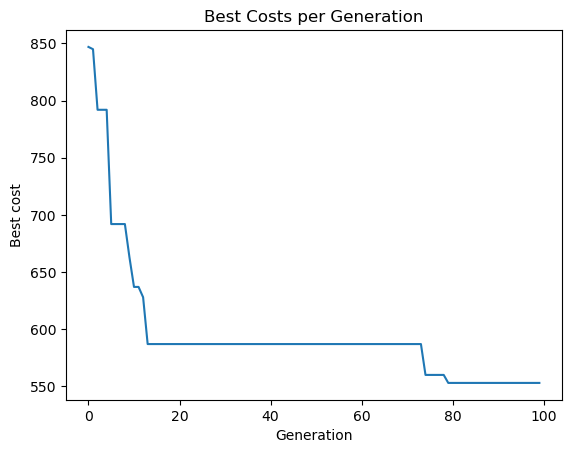

In [57]:
import matplotlib.pyplot as plt
best_costs_over_gens, _ = genetic_tsp()
plt.plot(best_costs_over_gens)
plt.title("Best Costs per Generation")
plt.xlabel("Generation")
plt.ylabel("Best cost")
plt.show()

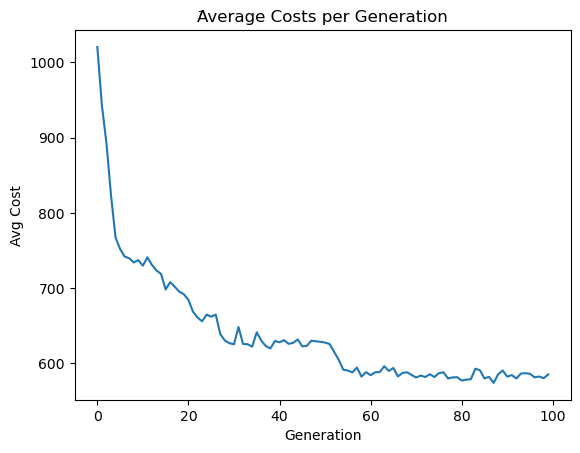

In [59]:
_, avg_costs_over_gens = genetic_tsp()
plt.plot(avg_costs_over_gens)
plt.title("َAverage Costs per Generation")
plt.xlabel("Generation")
plt.ylabel("Avg Cost")
plt.show()

In [61]:
all_runs_best = []  
num_runs = 30

for _ in range(num_runs):
    best_over_gens, _ = genetic_tsp()
    all_runs_best.append(best_over_gens)

# convert to numpy array to calculate the mean
all_runs_best = np.array(all_runs_best)  # 2D numpy array: rows = num_runs , columns = generations
mean_best_over_gens = np.mean(all_runs_best, axis=0)  # mean over 100 generation

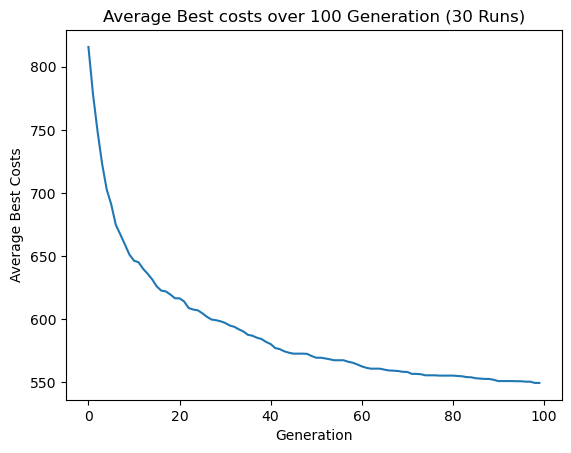

In [63]:
plt.plot(mean_best_over_gens)
plt.title("Average Best costs over 100 Generation (30 Runs)")
plt.xlabel("Generation")
plt.ylabel("Average Best Costs")
plt.show()